## 1. Word and character features

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, vstack, csr_matrix
from scipy.special import expit, logit
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer, TfidfTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import time

np.random.seed(42)

train = pd.read_csv('train.csv').sort_values('id').reset_index(drop=True)
unlabeled = pd.read_csv('unlabeled.csv')
test = pd.read_csv('test.csv')

fit_df, val_df = train_test_split(train, test_size=2000, stratify=train['label'], random_state=42)
fit_df = fit_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

X_train = fit_df['text'].astype(str)
y_train = fit_df['label']
X_val = val_df['text'].astype(str)
y_val = val_df['label']
X_unlabeled = unlabeled['text'].astype(str)

print(len(X_train), len(X_val), len(X_unlabeled))


8000 2000 3000


In [17]:
# try several text features with the same logistic regression model
representations = {
    'word_count': CountVectorizer(binary=True, min_df=2, max_features=70000),
    'word_tfidf_1gram': TfidfVectorizer(ngram_range=(1, 1), min_df=2,
                                       max_features=70000, sublinear_tf=True),
    'word_tfidf_1_2gram': TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                                         max_features=110000, sublinear_tf=True),
    'char_tfidf_3_5gram': Pipeline([
        ('hash', HashingVectorizer(analyzer='char', ngram_range=(3, 5),
                                   n_features=2**17, alternate_sign=False, norm=None)),
        ('tfidf', TfidfTransformer(sublinear_tf=True))
    ])
}

trained = {}
rows = []
for name, vec in representations.items():
    start = time.perf_counter()
    a = vec.fit_transform(X_train)
    b = vec.transform(X_val)
    clf = LogisticRegression(C=1.0, max_iter=1000, solver='liblinear', random_state=42)
    clf.fit(a, y_train)
    p_train = clf.predict_proba(a)[:, 1]
    p_val = clf.predict_proba(b)[:, 1]
    rows.append([name, a.shape[1], roc_auc_score(y_train, p_train),
                 roc_auc_score(y_val, p_val), time.perf_counter() - start])
    trained[name] = {'vec': vec, 'clf': clf, 'train_p': p_train, 'val_p': p_val}
    print(name, round(roc_auc_score(y_val, p_val), 4))

comparison = pd.DataFrame(rows, columns=['Features', 'Dimensions', 'Train AUC', 'Val AUC', 'Seconds'])
display(comparison.round(4))

char_vec = trained['char_tfidf_3_5gram']['vec']
char_clf = trained['char_tfidf_3_5gram']['clf']
p_char = trained['char_tfidf_3_5gram']['val_p']
p_word = trained['word_tfidf_1_2gram']['val_p']


word_count 0.9168
word_tfidf_1gram 0.9198
word_tfidf_1_2gram 0.9344
char_tfidf_3_5gram 0.96


,Features,Dimensions,Train AUC,Val AUC,Seconds
0,word_count,27711,1.0000,0.9168,0.9440
1,word_tfidf_1gram,27711,0.9838,0.9198,0.7545
2,word_tfidf_1_2gram,110000,0.9957,0.9344,2.4074
3,char_tfidf_3_5gram,131072,0.9947,0.9600,8.5014


word weight 0 AUC 0.95998
word weight 0.25 AUC 0.96026
word weight 0.5 AUC 0.95717
word weight 0.75 AUC 0.94875
word weight 1 AUC 0.93436


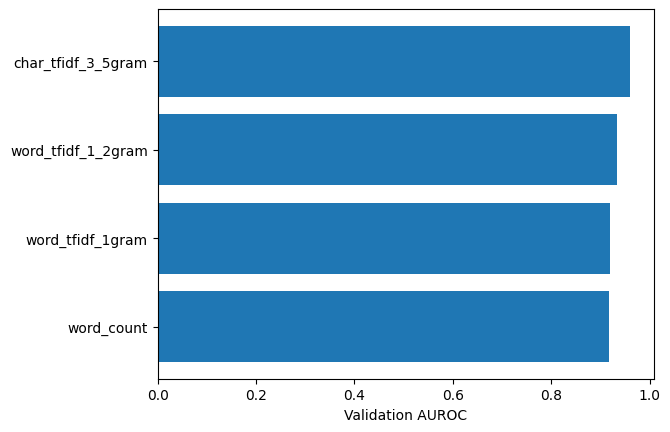

In [18]:
# some quick ensembles
for weight in [0, 0.25, 0.5, 0.75, 1]:
    p = (1-weight) * p_char + weight * p_word
    print('word weight', weight, 'AUC', round(roc_auc_score(y_val, p), 5))

plt.barh(comparison['Features'], comparison['Val AUC'])
plt.xlabel('Validation AUROC')
plt.show()


In [19]:
# first Kaggle try - character TF-IDF only (~0.842 public AUROC)
char_full = Pipeline([
    ('hash', HashingVectorizer(analyzer='char', ngram_range=(3, 5),
                               n_features=2**17, alternate_sign=False, norm=None)),
    ('tfidf', TfidfTransformer(sublinear_tf=True)),
    ('clf', LogisticRegression(C=1.0, max_iter=1000,
                               solver='liblinear', random_state=42))
])
char_full.fit(train['text'].astype(str), train['label'])
p_char_full_test = char_full.predict_proba(test['text'].astype(str))[:, 1]

pd.DataFrame({'id': test['id'], 'label': p_char_full_test}).to_csv(
    'char_tfidf_3-5gram_hash131072_logreg_v1.csv', index=False
)
print('saved first character model predictions')

saved first character model predictions


## 2. Unlabeled data

In [20]:
# pseudo-label the unlabeled set using the character model
Z_train = char_vec.transform(X_train)
Z_val = char_vec.transform(X_val)
Z_unlabeled = char_vec.transform(X_unlabeled)
p_unlabeled = char_clf.predict_proba(Z_unlabeled)[:, 1]

pseudo_results = [['Supervised only', 0, roc_auc_score(y_val, p_char)]]
for threshold in [0.80, 0.90, 0.95, 0.98]:
    keep = (p_unlabeled <= 1 - threshold) | (p_unlabeled >= threshold)
    pseudo_y = (p_unlabeled[keep] >= 0.5).astype(int)
    if keep.sum() == 0:
        continue
    X_more = vstack([Z_train, Z_unlabeled[keep]])
    y_more = np.concatenate([y_train, pseudo_y])
    weights = np.concatenate([np.ones(len(y_train)), np.full(keep.sum(), 0.5)])
    student = LogisticRegression(C=1.0, max_iter=1000, solver='liblinear', random_state=42)
    student.fit(X_more, y_more, sample_weight=weights)
    p = student.predict_proba(Z_val)[:, 1]
    pseudo_results.append([threshold, int(keep.sum()), roc_auc_score(y_val, p)])

pseudo_df = pd.DataFrame(pseudo_results, columns=['Threshold', 'Pseudo labels', 'Val AUC'])
display(pseudo_df.round(5))


,Threshold,Pseudo labels,Val AUC
0,Supervised only,0,0.95998
1,0.8,926,0.95941
2,0.9,214,0.95984
3,0.95,27,0.95996


In [21]:
# also try learning the IDF weights with the unlabeled texts included
corpus = pd.concat([X_train.reset_index(drop=True), X_unlabeled.reset_index(drop=True)])

adapt_vec = Pipeline([
    ('hash', HashingVectorizer(analyzer='char', ngram_range=(3, 5),
                               n_features=2**17, alternate_sign=False, norm=None)),
    ('tfidf', TfidfTransformer(sublinear_tf=True))
])
adapt_vec.fit(corpus)
adapt_clf = LogisticRegression(C=1.0, max_iter=1000, solver='liblinear', random_state=42)
adapt_clf.fit(adapt_vec.transform(X_train), y_train)
p_adapt = adapt_clf.predict_proba(adapt_vec.transform(X_val))[:, 1]

print('Original:', roc_auc_score(y_val, p_char))
print('With unlabeled IDF:', roc_auc_score(y_val, p_adapt))


Original: 0.959979
With unlabeled IDF: 0.959945


In [22]:
# look at a few mistakes from the character model
errors = val_df[['id', 'text', 'label']].copy()
errors['p_ai'] = p_char
errors['prediction'] = (errors['p_ai'] >= 0.5).astype(int)
errors['words'] = errors['text'].str.split().str.len()

display(errors[(errors['label'] == 0) & (errors['prediction'] == 1)]
        .sort_values('p_ai', ascending=False)[['id', 'p_ai', 'words']].head(5))
display(errors[(errors['label'] == 1) & (errors['prediction'] == 0)]
        .sort_values('p_ai')[['id', 'p_ai', 'words']].head(5))

errors['length_bin'] = pd.qcut(errors['words'], q=3, duplicates='drop')
for length_bin, part in errors.groupby('length_bin', observed=True):
    print(length_bin, len(part), round(roc_auc_score(part['label'], part['p_ai']), 4))


,id,p_ai,words
413,5234,0.743301,133
442,3743,0.736255,153
1615,3671,0.730809,165
131,6592,0.698676,233
942,3364,0.624334,184


,id,p_ai,words
1659,1524,0.105517,124
663,3062,0.128680,170
994,9490,0.137520,288
1709,8105,0.171879,197
1525,2903,0.213013,129


(75.999, 172.333] 667 0.9496
(172.333, 237.0] 670 0.9625
(237.0, 350.0] 663 0.9734


## 3. Formatting

In [23]:
# see if text layout is different between human and AI passages
# use the same features on all groups
surface = {}
for name, texts in [('train', X_train), ('val', X_val), ('test', test['text'].astype(str))]:
    t = texts.reset_index(drop=True)
    words = t.str.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?")
    surface[name] = pd.DataFrame({
        'blank': t.str.contains('\n\n', regex=False).astype(int),
        'newlines': t.str.count('\n'),
        'list': t.str.contains(r'(?m)^[ \t]*(?:[-*•]|\d+[.)])[ \t]+').astype(int),
        'heading': t.str.contains(r'(?m)^[ \t]*#{1,6}[ \t]+').astype(int),
        'word_count': t.str.split().str.len(),
        'unique_ratio': words.map(lambda w: len(set(x.lower() for x in w))/max(len(w), 1)),
        'avg_word_len': words.map(lambda w: sum(map(len, w))/max(len(w), 1)),
        'punct_rate': t.str.count(r'[.,;:!?]')/t.str.len().clip(lower=1),
        'digit_rate': t.str.count(r'\d')/t.str.len().clip(lower=1),
        'sentence_length_proxy': t.str.split().str.len()/t.str.count(r'[.!?]').clip(lower=1)
    })

audit_fit = surface['train']
audit_val = surface['val']
audit_test = surface['test']

display(pd.DataFrame({
    'Human': audit_fit[y_train.eq(0)].mean(),
    'AI': audit_fit[y_train.eq(1)].mean(),
    'Test': audit_test.mean()
}).round(3))


,Human,AI,Test
blank,0.000,0.654,0.319
newlines,5.798,12.211,12.450
list,0.009,0.160,0.048
heading,0.000,0.022,0.004
word_count,209.334,208.720,216.972
unique_ratio,0.587,0.628,0.590
avg_word_len,4.755,5.006,4.707
punct_rate,0.018,0.018,0.020
digit_rate,0.012,0.013,0.007
sentence_length_proxy,20.909,29.785,28.996


In [24]:
# how good is each feature on its own
rows = []
for col in audit_fit.columns:
    human_avg = audit_fit.loc[y_train.eq(0), col].mean()
    ai_avg = audit_fit.loc[y_train.eq(1), col].mean()
    direction = 1 if ai_avg > human_avg else -1
    rows.append([col, roc_auc_score(y_val, direction * audit_val[col])])
display(pd.DataFrame(rows, columns=['Feature', 'Val AUC']).sort_values('Val AUC', ascending=False))


,Feature,Val AUC
0,blank,0.841500
6,avg_word_len,0.595622
1,newlines,0.591909
5,unique_ratio,0.585167
2,list,0.579000
9,sentence_length_proxy,0.513746
7,punct_rate,0.509022
3,heading,0.508000
4,word_count,0.502553
8,digit_rate,0.476183


In [25]:
# check how much model changes when remove formatting
p_orig = p_char
rows = [['Original', roc_auc_score(y_val, p_orig), 0]]
for name, texts in [
    ('Remove blank lines', X_val.str.replace(r'\n[ \t]*\n+', '\n', regex=True)),
    ('Normalize whitespace', X_val.str.replace(r'\s+', ' ', regex=True).str.strip())
]:
    p = char_clf.predict_proba(char_vec.transform(texts))[:, 1]
    rows.append([name, roc_auc_score(y_val, p), np.abs(p - p_orig).mean()])
display(pd.DataFrame(rows, columns=['Text', 'Val AUC', 'Mean change']).round(4))

# retrain with normalized whitespace as well
X_train_clean = X_train.str.replace(r'\s+', ' ', regex=True).str.strip()
X_val_clean = X_val.str.replace(r'\s+', ' ', regex=True).str.strip()
clean_model = Pipeline([
    ('hash', HashingVectorizer(analyzer='char', ngram_range=(3, 5),
                               n_features=2**17, alternate_sign=False, norm=None)),
    ('tfidf', TfidfTransformer(sublinear_tf=True)),
    ('clf', LogisticRegression(C=1.0, max_iter=1000, solver='liblinear', random_state=42))
])
clean_model.fit(X_train_clean, y_train)
p_clean = clean_model.predict_proba(X_val_clean)[:, 1]
print('Retrained with normalized text:', roc_auc_score(y_val, p_clean))


,Text,Val AUC,Mean change
0,Original,0.9600,0.0000
1,Remove blank lines,0.9419,0.0160
2,Normalize whitespace,0.9269,0.0438


Retrained with normalized text: 0.9437239999999999


In [26]:
# adding a few explicit features to the character TF-IDF
format_cols = ['blank', 'newlines', 'list', 'heading']
lexical_cols = ['word_count', 'unique_ratio', 'avg_word_len', 'punct_rate', 'digit_rate', 'sentence_length_proxy']
extra_results = []
augmented_models = {}
for name, cols in [('Formatting', format_cols), ('Lexical', lexical_cols),
                   ('Both', format_cols + lexical_cols)]:
    scaler = StandardScaler()
    Z_extra_train = scaler.fit_transform(audit_fit[cols])
    Z_extra_val = scaler.transform(audit_val[cols])
    X_aug = hstack([Z_train, csr_matrix(0.2 * Z_extra_train)])
    V_aug = hstack([Z_val, csr_matrix(0.2 * Z_extra_val)])
    clf = LogisticRegression(C=1.0, max_iter=1000, solver='liblinear', random_state=42)
    clf.fit(X_aug, y_train)
    p = clf.predict_proba(V_aug)[:, 1]
    extra_results.append([name, roc_auc_score(y_val, p)])
    augmented_models[name] = (clf, scaler, cols, p)
display(pd.DataFrame(extra_results, columns=['Extra features', 'Val AUC']).round(5))


,Extra features,Val AUC
0,Formatting,0.98766
1,Lexical,0.95630
2,Both,0.98223


In [27]:
# compare on the passages without blank lines too
no_blank = audit_val['blank'].eq(0).to_numpy()
rows = [['Character only', roc_auc_score(y_val, p_char), roc_auc_score(y_val[no_blank], p_char[no_blank])],
        ['Normalized text', roc_auc_score(y_val, p_clean), roc_auc_score(y_val[no_blank], p_clean[no_blank])]]
for name, (clf, scaler, cols, p) in augmented_models.items():
    rows.append([name, roc_auc_score(y_val, p), roc_auc_score(y_val[no_blank], p[no_blank])])
display(pd.DataFrame(rows, columns=['Model', 'All', 'No blank']).round(5))


,Model,All,No blank
0,Character only,0.95998,0.97025
1,Normalized text,0.94372,0.95871
2,Formatting,0.98766,0.96107
3,Lexical,0.95630,0.96826
4,Both,0.98223,0.94395


In [28]:
# instead of retraining, add a bonus to the log-odds when there is a blank line
blank_val = audit_val['blank'].to_numpy()
blank_test = audit_test['blank'].to_numpy()
p_char_test = char_clf.predict_proba(char_vec.transform(test['text'].astype(str)))[:, 1]

bonus_rows = []
for bonus in [0, 1, 2, 3, 4, 6]:
    p = expit(logit(np.clip(p_char, 1e-6, 1-1e-6)) + bonus * blank_val)
    bonus_rows.append([bonus, roc_auc_score(y_val, p), roc_auc_score(y_val[no_blank], p[no_blank])])
display(pd.DataFrame(bonus_rows, columns=['Bonus', 'Val AUC', 'No blank']).round(5))

p_blank2 = expit(logit(np.clip(p_char, 1e-6, 1-1e-6)) + 2*blank_val)
print('Blank bonus 2:', roc_auc_score(y_val, p_blank2))


,Bonus,Val AUC,No blank
0,0,0.95998,0.97025
1,1,0.98734,0.97025
2,2,0.99038,0.97025
3,3,0.99057,0.97025
4,4,0.99057,0.97025
5,6,0.99057,0.97025


Blank bonus 2: 0.990382


In [29]:
# second try, blank line give an AI log-odds bonus of 2
# public AUROC was 0.95434
blank_full_test = test['text'].astype(str).str.contains('\n\n', regex=False).to_numpy()
p_blank_full_test = expit(
    logit(np.clip(p_char_full_test, 1e-6, 1-1e-6)) + 2 * blank_full_test
)

pd.DataFrame({'id': test['id'], 'label': p_blank_full_test}).to_csv(
    'char_tfidf_3-5gram_logreg_blankbonus2_v2.csv', index=False
)
print('saved character model + blank-line bonus')

saved character model + blank-line bonus


## 4. More experiments

In [30]:
# other small formatting clues, mostly for texts without blank lines
artifacts = {}
for name, texts in [('train', X_train), ('val', X_val), ('test', test['text'].astype(str))]:
    t = texts.reset_index(drop=True)
    artifacts[name] = pd.DataFrame({
        'blank': t.str.contains('\n\n', regex=False).astype(int),
        'exclamation': t.str.contains('!', regex=False).astype(int),
        'semicolon': t.str.contains(';', regex=False).astype(int),
        'double_space': t.str.contains('  ', regex=False).astype(int),
        '5plus_newlines': (t.str.count('\n') >= 5).astype(int),
        '20plus_newlines': (t.str.count('\n') >= 20).astype(int),
        'wrapped_line': t.str.contains(r'(?m)^.{60,80}$').astype(int)
    })

art_fit, art_val, art_test = artifacts['train'], artifacts['val'], artifacts['test']
rows = []
for col in art_fit.columns.drop('blank'):
    human = art_fit.loc[y_train.eq(0) & art_fit['blank'].eq(0), col].mean()
    ai = art_fit.loc[y_train.eq(1) & art_fit['blank'].eq(0), col].mean()
    tst = art_test.loc[art_test['blank'].eq(0), col].mean()
    direction = 1 if ai > human else -1
    auc = roc_auc_score(y_val[no_blank], direction * art_val.loc[no_blank, col])
    rows.append([col, human, ai, tst, auc])
display(pd.DataFrame(rows, columns=['Feature', 'Human', 'AI', 'Test', 'AUC']).round(4))


,Feature,Human,AI,Test,AUC
0,exclamation,0.0505,0.3054,0.1385,0.6468
1,semicolon,0.1703,0.3242,0.2299,0.5927
2,double_space,0.1508,0.0253,0.1140,0.5660
3,5plus_newlines,0.4008,0.0810,0.3430,0.6707
4,20plus_newlines,0.0385,0.0130,0.1717,0.5086
5,wrapped_line,0.2700,0.0514,0.1707,0.6303


In [31]:
# small adjustments to the blank-line bonus
settings = {
    'Blank only': (0, 0, 0),
    '+ Exclamation': (0.5, 0, 0),
    '+ Wrapped line': (0, 0.5, 0),
    '+ Double space': (0, 0, 0.5),
    '+ All three': (0.4, 0.4, 0.3)
}
rows = []
for name, (ex, wrapped, space) in settings.items():
    scores = logit(np.clip(p_char, 1e-6, 1-1e-6)) + 2*blank_val
    scores += (1-blank_val) * (ex*art_val['exclamation'].to_numpy()
                    - wrapped*art_val['wrapped_line'].to_numpy()
                    - space*art_val['double_space'].to_numpy())
    p = expit(scores)
    rows.append([name, roc_auc_score(y_val, p), roc_auc_score(y_val[no_blank], p[no_blank])])
display(pd.DataFrame(rows, columns=['Setting', 'Val AUC', 'No blank']).round(5))


,Setting,Val AUC,No blank
0,Blank only,0.99038,0.97025
1,+ Exclamation,0.99059,0.97094
2,+ Wrapped line,0.99002,0.96910
3,+ Double space,0.99181,0.97462
4,+ All three,0.99139,0.97333


In [32]:
# train a separate model just for examples without blank lines
mask_train = art_fit['blank'].eq(0).to_numpy()
X_special = X_train[mask_train]
y_special = y_train[mask_train]
specialist = Pipeline([
    ('hash', HashingVectorizer(analyzer='char', ngram_range=(3, 5),
                               n_features=2**17, alternate_sign=False, norm=None)),
    ('tfidf', TfidfTransformer(sublinear_tf=True)),
    ('clf', LogisticRegression(C=1.0, max_iter=1000, solver='liblinear', random_state=42))
])
specialist.fit(X_special, y_special)
p_special = specialist.predict_proba(X_val)[:, 1]
p_special_hybrid = p_blank2.copy()
p_special_hybrid[no_blank] = p_special[no_blank]
for name, p in [('Current', p_blank2), ('Specialist only', p_special), ('Hybrid', p_special_hybrid)]:
    print(name, round(roc_auc_score(y_val, p), 5),
          round(roc_auc_score(y_val[no_blank], p[no_blank]), 5))


Current 0.99038 0.97025
Specialist only 0.77726 0.95701
Hybrid 0.98637 0.95701


In [33]:
# try word/character weights again, now with the blank-line bonus
rows = []
for word_weight in [0, 0.1, 0.25, 0.5, 0.75, 1.0]:
    mix = (1-word_weight)*p_char + word_weight*p_word
    p = expit(logit(np.clip(mix, 1e-6, 1-1e-6)) + 2*blank_val)
    rows.append([word_weight, roc_auc_score(y_val, p), roc_auc_score(y_val[no_blank], p[no_blank])])
display(pd.DataFrame(rows, columns=['Word weight', 'Val AUC', 'No blank']).round(5))


,Word weight,Val AUC,No blank
0,0.00,0.99038,0.97025
1,0.10,0.99088,0.97162
2,0.25,0.99143,0.97321
3,0.50,0.99141,0.97301
4,0.75,0.98951,0.96697
5,1.00,0.98534,0.95385


In [34]:
# quick check of a few final combinations
mix = 0.75*p_char + 0.25*p_word
p_mix_blank = expit(logit(np.clip(mix, 1e-6, 1-1e-6)) + 2*blank_val)
p_mix_space = expit(logit(np.clip(mix, 1e-6, 1-1e-6)) + 2*blank_val
                    - 0.5*(1-blank_val)*art_val['double_space'].to_numpy())

for name, p in [('Char + blank', p_blank2),
                ('Word/char + blank', p_mix_blank),
                ('Word/char + blank + double spaces', p_mix_space)]:
    print(name, roc_auc_score(y_val, p), roc_auc_score(y_val[no_blank], p[no_blank]))


Char + blank 0.990382 0.9702492113564669
Word/char + blank 0.991431 0.9732050473186119
Word/char + blank + double spaces 0.992745 0.9773091482649843


In [35]:
# third submission attempt, mix some word features in and penalize double spaces
# public AUROC was 0.95687
word_full = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              max_features=110000, sublinear_tf=True)),
    ('clf', LogisticRegression(C=1.0, max_iter=1000,
                               solver='liblinear', random_state=42))
])
word_full.fit(train['text'].astype(str), train['label'])
p_word_full_test = word_full.predict_proba(test['text'].astype(str))[:, 1]

p_blend_full_test = 0.75 * p_char_full_test + 0.25 * p_word_full_test
double_space_test = test['text'].astype(str).str.contains('  ', regex=False).to_numpy()
p_blend_adjusted = expit(
    logit(np.clip(p_blend_full_test, 1e-6, 1-1e-6))
    + 2 * blank_full_test
    - 0.5 * (~blank_full_test) * double_space_test
)

pd.DataFrame({'id': test['id'], 'label': p_blend_adjusted}).to_csv(
    'word25_char75_blank2_doublespace05_v3.csv', index=False
)
print('saved word/character + formatting predictions')

saved word/character + formatting predictions


In [36]:
# Some final experiments
# Word trigrams
word3_vec = TfidfVectorizer(
    ngram_range=(1, 3), min_df=2,
    max_features=150000, sublinear_tf=True
)

X_word3 = word3_vec.fit_transform(train["text"].astype(str))
T_word3 = word3_vec.transform(test["text"].astype(str))

word3_clf = LogisticRegression(
    C=1.0, max_iter=1000, solver="liblinear", random_state=42
)
word3_clf.fit(X_word3, train["label"])

p_word3 = word3_clf.predict_proba(T_word3)[:, 1]
p_mix3 = 0.75 * p_char_full_test + 0.25 * p_word3

p_exp1 = expit(
    logit(np.clip(p_mix3, 1e-6, 1-1e-6))
    + 2 * blank_full_test
    - 0.5 * (~blank_full_test) * double_space_test
)

pd.DataFrame({"id": test["id"], "label": p_exp1}).to_csv(
    "experiment_word_trigrams.csv", index=False
)


# Remove double-space penalty
p_exp2 = expit(
    logit(np.clip(p_blend_full_test, 1e-6, 1-1e-6))
    + 2 * blank_full_test
)

pd.DataFrame({"id": test["id"], "label": p_exp2}).to_csv(
    "experiment_no_double_space.csv", index=False
)